In [ ]:
import warnings
warnings.filterwarnings(action="ignore", message=r"datetime.datetime.utcnow")

# PERSIAPAN

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/Pertemuan/PRAK8SML') # ganti dengan folder hasil copy kalian

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df_full = pd.read_csv("voters.csv")
df_full.head()

,VoterID,Age,Interest,OnlineHours,FirstTime,StableJob,Community,InfoSource,Education,Candidate
0,1,54.0,6.0,7.0,1.0,No,No,TV,Primary,Paslon_A
1,2,51.0,NaN,NaN,0.0,NaN,No,TV,NaN,Paslon_A
2,3,49.0,8.0,1.0,0.0,Yes,No,SocialMedia,Secondary,Paslon_C
3,4,30.0,4.0,3.0,0.0,Yes,Yes,FriendsFamily,NaN,Paslon_C
4,5,66.0,1.0,4.0,0.0,Yes,Yes,SocialMedia,Tertiary,Paslon_A


In [ ]:
df = df_full.drop(columns=['VoterID'], axis=1)
df.columns = [
    'age',
    'interest',
    'online',
    'first',
    'job_stable',
    'community',
    'info_source',
    'edu',
    'candidate',
    ]
for c in ["first"]:
  df[c] = df[c].astype("Int64").astype("object")
df.head()

,age,interest,online,first,job_stable,community,info_source,edu,candidate
0,54.0,6.0,7.0,1,No,No,TV,Primary,Paslon_A
1,51.0,NaN,NaN,0,NaN,No,TV,NaN,Paslon_A
2,49.0,8.0,1.0,0,Yes,No,SocialMedia,Secondary,Paslon_C
3,30.0,4.0,3.0,0,Yes,Yes,FriendsFamily,NaN,Paslon_C
4,66.0,1.0,4.0,0,Yes,Yes,SocialMedia,Tertiary,Paslon_A


# EDA

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3675 entries, 0 to 3674
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          3356 non-null   float64
 1   interest     3355 non-null   float64
 2   online       3286 non-null   float64
 3   first        3317 non-null   object 
 4   job_stable   3322 non-null   object 
 5   community    3316 non-null   object 
 6   info_source  3295 non-null   object 
 7   edu          3346 non-null   object 
 8   candidate    3675 non-null   object 
dtypes: float64(3), object(6)
memory usage: 258.5+ KB


In [ ]:
df.describe(include = 'number')

,age,interest,online
count,3356.000000,3355.000000,3286.000000
mean,53.040524,6.354993,4.941570
std,33.023437,3.964218,5.915663
min,17.000000,1.000000,0.000000
25%,30.000000,3.000000,2.000000
50%,46.000000,6.000000,3.000000
75%,66.250000,9.000000,6.000000
max,236.000000,20.000000,57.000000


In [ ]:
df.describe(include = ['category', 'object'])

,first,job_stable,community,info_source,edu,candidate
count,3317,3322,3316,3295,3346,3675
unique,2,2,2,4,3,3
top,0,Yes,No,OnlineNews,Secondary,Paslon_C
freq,2255,1929,2018,1111,1661,1359


# PREPROCESSING

## Data Cleaning

### Missing Value

Pemeriksaan

In [ ]:
print('Total Missing Value')
print(df.isnull().sum())

Total Missing Value
age            319
interest       320
online         389
first          358
job_stable     353
community      359
info_source    380
edu            329
candidate        0
dtype: int64


Penanganan

In [ ]:
df_no_misval = df.copy()

# Imputasi dengan rata-rata
for col in ['age', 'interest', 'online']:
  df_no_misval[col] = df_no_misval[col].fillna(df_no_misval[col].mean())

# Hapus baris
df_no_misval = df_no_misval.dropna(axis=0)

Pemeriksaan Kembali

In [ ]:
print('Total Missing Value')
print(df_no_misval.isnull().sum())

Total Missing Value
age            0
interest       0
online         0
first          0
job_stable     0
community      0
info_source    0
edu            0
candidate      0
dtype: int64


### Outlier

Pemeriksaan

In [ ]:
def cek_outlier(df, figsize=(5, 1), dpi=100):
    kolom = df.select_dtypes(include=[np.number]).columns
    if len(kolom) == 0:
        print("Tidak ada kolom numerik.")
        return

    df_checked = df[kolom]
    df_checked.plot(
        kind="box", subplots=True,
        layout=(len(kolom), 1), figsize=(figsize[0], len(kolom) * figsize[1]),
        sharex=False, vert=False,
    )

    fig = plt.gcf()
    fig.set_dpi(dpi)
    fig.subplots_adjust(hspace=0.6)

    plt.show()

Boxplot Seluruh Variabel Numerik Sebelum Pembersihan Outlier


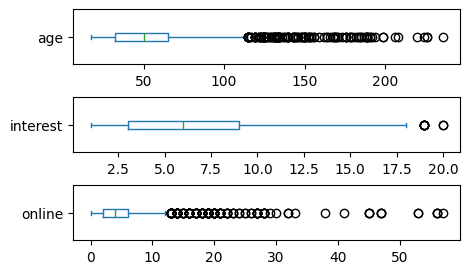

In [ ]:
print("Boxplot Seluruh Variabel Numerik Sebelum Pembersihan Outlier")
cek_outlier(df_no_misval)

Penanganan

In [ ]:
def hapus_outlier(df, kolom=None, max_iter=1):
    kolom = df.select_dtypes(include=[np.number]).columns

    df_clean = df.copy()
    for i in range(max_iter):
        before = df_clean.shape[0]

        mask = pd.Series(True, index=df_clean.index)
        for c in kolom:
            Q1, Q3 = df_clean[c].quantile([0.25, 0.75])
            IQR = Q3 - Q1
            mask &= df_clean[c].between(Q1 - 1.5*IQR, Q3 + 1.5*IQR)

        df_clean = df_clean[mask]
        after = df_clean.shape[0]

        if before == after:  # berhenti kalau tidak ada perubahan
            break
        print(f'Iterasi {i+1}: {before} -> {after} sampel')

    print(f'HASIL: {len(df)} baris dihapus dan {len(df_clean)} baris tersisa setelah {i} iterasi.')
    return df_clean

In [ ]:
df_no_outlier = df_no_misval.copy()
df_no_outlier = hapus_outlier(df_no_outlier, max_iter=10)

Iterasi 1: 2217 -> 1982 sampel
Iterasi 2: 1982 -> 1868 sampel
Iterasi 3: 1868 -> 1865 sampel
HASIL: 2217 baris dihapus dan 1865 baris tersisa setelah 3 iterasi.


Pemeriksaan Kembali

Boxplot Seluruh Variabel Numerik Setelah Pembersihan Outlier


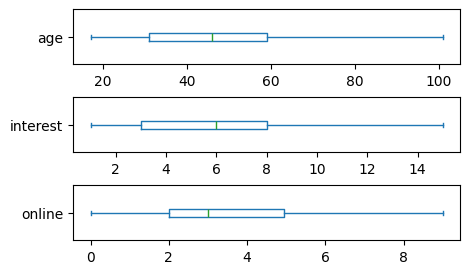

In [ ]:
print("Boxplot Seluruh Variabel Numerik Setelah Pembersihan Outlier")
cek_outlier(df_no_outlier)

### Data Duplikat

Pemeriksaan

In [ ]:
print(df_no_outlier.duplicated().sum(), 'baris terduplikat')

559 baris terduplikat


Penanganan

In [ ]:
df_no_dup = df_no_outlier.copy()
df_no_dup.drop_duplicates(inplace=True)

Pemeriksaan Kembali

In [ ]:
print(df_no_dup.duplicated().sum(), 'baris terduplikat')

0 baris terduplikat


## Splitting

In [ ]:
df_clean = df_no_dup.copy()

In [ ]:
y_col = 'candidate'

# pisah X dan y
X = df_clean.drop(columns=y_col)
y_cat = df_clean[y_col].astype('category') # encode target ke kategori numerik
y = y_cat.cat.codes # 0, 1, 2, ...

class_names = list(y_cat.cat.categories)
n_classes = len(class_names)

print(f'Variabel prediktor:', ', '.join(X.columns.values))
print(f'Variabel target   : {y_col} ({n_classes} kelas)')
print('Mapping kelas:', {i: c for i, c in enumerate(class_names)})

Variabel prediktor: age, interest, online, first, job_stable, community, info_source, edu
Variabel target   : candidate (3 kelas)
Mapping kelas: {0: 'Paslon_A', 1: 'Paslon_B', 2: 'Paslon_C'}


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123, stratify=y
)

print("Ukuran data train:", X_train.shape[0], 'baris')
print("Ukuran data test :", X_test.shape[0], 'baris')

Ukuran data train: 1044 baris
Ukuran data test : 262 baris


## Encoding

In [ ]:
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns

X_train_dum = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype='uint8')
X_test_dum = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype='uint8')
X_test_dum = X_test_dum.reindex(columns=X_train_dum.columns, fill_value=0)

print(f'Ada {len(X_train_dum.columns)} variabel X.\n')
X_train_dum.info()

Ada 11 variabel X.

<class 'pandas.core.frame.DataFrame'>
Index: 1044 entries, 2197 to 663
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      1044 non-null   float64
 1   interest                 1044 non-null   float64
 2   online                   1044 non-null   float64
 3   first_1                  1044 non-null   uint8  
 4   job_stable_Yes           1044 non-null   uint8  
 5   community_Yes            1044 non-null   uint8  
 6   info_source_OnlineNews   1044 non-null   uint8  
 7   info_source_SocialMedia  1044 non-null   uint8  
 8   info_source_TV           1044 non-null   uint8  
 9   edu_Secondary            1044 non-null   uint8  
 10  edu_Tertiary             1044 non-null   uint8  
dtypes: float64(3), uint8(8)
memory usage: 40.8 KB


## Standardisasi

In [ ]:
from sklearn.preprocessing import StandardScaler

num_cols = X_train.select_dtypes(include=[np.number]).columns

scaler = StandardScaler()
scaler.fit(X_train_dum[num_cols])

X_train_std = X_train_dum.copy()
X_test_std  = X_test_dum.copy()
X_train_std[num_cols] = scaler.transform(X_train_dum[num_cols])
X_test_std[num_cols]  = scaler.transform(X_test_dum[num_cols])

In [ ]:
pd.DataFrame({
    "mean_before": X_train_dum[num_cols].mean(),
    "std_before":  X_train_dum[num_cols].std(ddof=0),
    "mean_after":  X_train_std[num_cols].mean(),
    "std_after":   X_train_std[num_cols].std(ddof=0),
}).round(3)

,mean_before,std_before,mean_after,std_after
age,48.995,17.951,0.0,1.0
interest,5.576,2.930,-0.0,1.0
online,3.235,2.192,-0.0,1.0


# ANN: KLASIFIKASI

In [ ]:
import torch
import torch.nn as nn

## Persiapan

### Konversi ke Array

In [ ]:
Xtr = torch.tensor(X_train_std.values, dtype=torch.float32)
Xte = torch.tensor(X_test_std.values,  dtype=torch.float32)

ytr = torch.tensor(y_train.values, dtype=torch.long)
yte = torch.tensor(y_test.values,  dtype=torch.long)

print('Matriks X training:')
print(Xtr)
print(f'Ukuran: {list(Xtr.shape)}')

print('\nVektor y training:')
print(ytr)
print(f'Ukuran: {list(ytr.shape)}')

Matriks X training:
tensor([[-0.2226,  0.8274, -0.5635,  ...,  1.0000,  1.0000,  0.0000],
        [-0.5568, -0.1966,  0.7783,  ...,  0.0000,  1.0000,  0.0000],
        [ 1.2815, -1.5621,  0.7783,  ...,  0.0000,  0.0000,  0.0000],
        ...,
        [-0.3897,  0.1447,  1.2611,  ...,  1.0000,  0.0000,  1.0000],
        [-0.2226, -0.1966,  0.7783,  ...,  1.0000,  1.0000,  0.0000],
        [ 1.1701, -0.5380, -0.5635,  ...,  0.0000,  1.0000,  0.0000]])
Ukuran: [1044, 11]

Vektor y training:
tensor([0, 2, 0,  ..., 1, 0, 1])
Ukuran: [1044]


### Arsitektur Model

In [ ]:
input_dim = Xtr.shape[1]
hidden_dim_1 = 16
hidden_dim_2 = 8
output_dim = n_classes

model = nn.Sequential(
    nn.Linear(input_dim, hidden_dim_1),
    nn.ReLU(),
    nn.Linear(hidden_dim_1, hidden_dim_2),
    nn.ReLU(),
    nn.Linear(hidden_dim_2, output_dim),
)
model

Sequential(
  (0): Linear(in_features=11, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)

### Loss dan Optimizer

In [ ]:
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

## Training

In [ ]:
n_epochs    = 500
print_every = 50

loss_history = []
acc_history  = []

for epoch in range(n_epochs):
    model.train()
    opt.zero_grad()
    logits = model(Xtr)
    loss = loss_fn(logits, ytr)
    loss.backward()
    opt.step()

    # hitung metrik training tiap epoch
    with torch.no_grad():
        pred_tr = logits.argmax(1)
        acc_tr  = (pred_tr == ytr).float().mean().item()

    # simpan ke list
    loss_history.append(loss.item())
    acc_history.append(acc_tr)

    # print tiap beberapa epoch
    if (epoch + 1) % print_every == 0:
        print(f"Epoch {epoch+1:04d} | Loss: {loss.item():.4f} | Training Acc: {acc_tr:.4f}")

Epoch 0050 | Loss: 1.0005 | Training Acc: 0.5182
Epoch 0100 | Loss: 0.8729 | Training Acc: 0.6418
Epoch 0150 | Loss: 0.7532 | Training Acc: 0.6992
Epoch 0200 | Loss: 0.7203 | Training Acc: 0.7050
Epoch 0250 | Loss: 0.7093 | Training Acc: 0.7031
Epoch 0300 | Loss: 0.7003 | Training Acc: 0.7126
Epoch 0350 | Loss: 0.6922 | Training Acc: 0.7136
Epoch 0400 | Loss: 0.6841 | Training Acc: 0.7136
Epoch 0450 | Loss: 0.6757 | Training Acc: 0.7203
Epoch 0500 | Loss: 0.6679 | Training Acc: 0.7232


In [ ]:
def plot_line(x, y, xlabel, ylabel, title, color=None, figsize=(6, 3), dpi=100):
    print(title)

    plt.figure(figsize=figsize, dpi=dpi)
    plt.plot(x, y, color=color)

    ax = plt.gca()
    ax.set_axisbelow(True)
    ax.grid(True, axis="y", linestyle="-", alpha=0.5)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.show()

Training Loss per Epoch


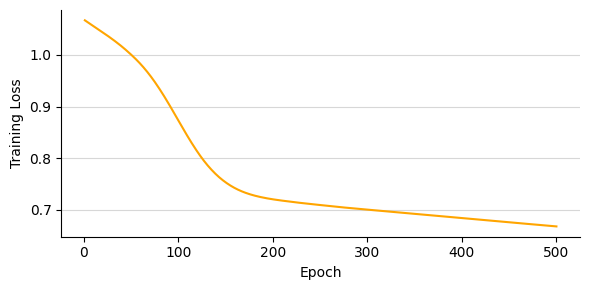


Training Accuracy per Epoch


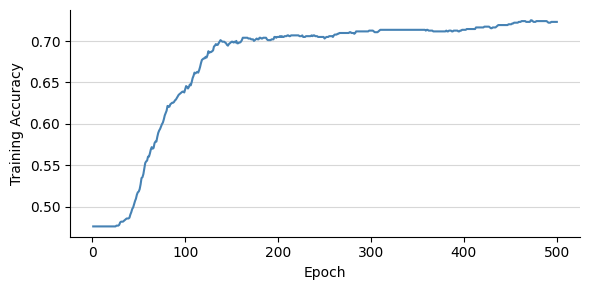

In [ ]:
epochs = range(1, n_epochs + 1)

plot_line(
    x=epochs,
    y=loss_history,
    xlabel="Epoch",
    ylabel="Training Loss",
    title="Training Loss per Epoch",
    color="orange",
)
print()

plot_line(
    x=epochs,
    y=acc_history,
    xlabel="Epoch",
    ylabel="Training Accuracy",
    title="Training Accuracy per Epoch",
    color="steelblue",
)

## Testing

In [ ]:
model.eval()
with torch.no_grad():
    logits_tr = model(Xtr)
    logits_te = model(Xte)

    y_pred_tr = logits_tr.argmax(1)
    y_pred_te = logits_te.argmax(1)

train_acc = (y_pred_tr == ytr).float().mean().item()
test_acc  = (y_pred_te == yte).float().mean().item()

print(f"Train Accuracy : {train_acc:.4f} (setelah {n_epochs} epoch)")
print(f"Test  Accuracy : {test_acc:.4f}")

Train Accuracy : 0.7232 (setelah 500 epoch)
Test  Accuracy : 0.6069


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = yte.cpu().numpy()
y_pred = y_pred_te.cpu().numpy()

labels = class_names
cm_ann = confusion_matrix(y_true, y_pred)

print("Sensitivity & Specificity per class:")

sens_ann = []
spec_ann = []

for i, cls in enumerate(labels):
    tp = cm_ann[i, i]
    fn = cm_ann[i, :].sum() - tp
    fp = cm_ann[:, i].sum() - tp
    tn = cm_ann.sum() - tp - fn - fp

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    sens_ann.append(sensitivity)
    spec_ann.append(specificity)

    print(f"Jika kategori {cls} adalah kelas positif -> "
          f"Sensitivity: {sensitivity:.4f} | Specificity: {specificity:.4f}")

Sensitivity & Specificity per class:
Jika kategori Paslon_A adalah kelas positif -> Sensitivity: 0.7419 | Specificity: 0.7174
Jika kategori Paslon_B adalah kelas positif -> Sensitivity: 0.3906 | Specificity: 0.7929
Jika kategori Paslon_C adalah kelas positif -> Sensitivity: 0.5676 | Specificity: 0.8777


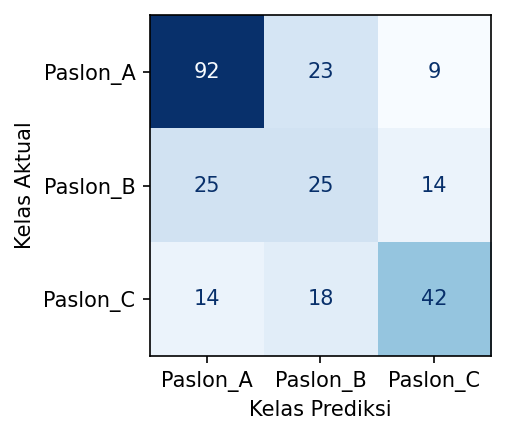

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3), dpi=150)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_ann, display_labels=labels)
disp.plot(values_format=".0f", cmap="Blues", colorbar=False, ax=ax)

ax.set_xlabel("Kelas Prediksi")
ax.set_ylabel("Kelas Aktual")

plt.tight_layout()
plt.show()

## Prediksi

In [ ]:
X_new_df = pd.DataFrame([
    {
        "age": 19,
        "interest": 9,
        "online": 12,
        "first_1": 1,
        "job_stable_Yes": 0,
        "community_Yes": 0,
        "info_source_OnlineNews": 0,
        "info_source_SocialMedia": 1,
        "info_source_TV": 0,
        "edu_Secondary": 1,
        "edu_Tertiary": 0,
    },
    {
        "age": 32,
        "interest": 6,
        "online": 4,
        "first_1": 0,
        "job_stable_Yes": 1,
        "community_Yes": 1,
        "info_source_OnlineNews": 1,
        "info_source_SocialMedia": 0,
        "info_source_TV": 0,
        "edu_Secondary": 0,
        "edu_Tertiary": 1,
    },
    {
        "age": 58,
        "interest": 3,
        "online": 1,
        "first_1": 0,
        "job_stable_Yes": 1,
        "community_Yes": 0,
        "info_source_OnlineNews": 0,
        "info_source_SocialMedia": 0,
        "info_source_TV": 1,
        "edu_Secondary": 0,
        "edu_Tertiary": 0,
    },
])
X_new_df = X_new_df[X_train_dum.columns]
X_new_df

,age,interest,online,first_1,job_stable_Yes,community_Yes,info_source_OnlineNews,info_source_SocialMedia,info_source_TV,edu_Secondary,edu_Tertiary
0,19,9,12,1,0,0,0,1,0,1,0
1,32,6,4,0,1,1,1,0,0,0,1
2,58,3,1,0,1,0,0,0,1,0,0


In [ ]:
X_new_std = X_new_df.copy()
X_new_std[num_cols] = scaler.transform(X_new_std[num_cols])

X_new = torch.tensor(X_new_std.values, dtype=torch.float32)
X_new

tensor([[-1.6709,  1.1688,  3.9980,  1.0000,  0.0000,  0.0000,  0.0000,  1.0000,
          0.0000,  1.0000,  0.0000],
        [-0.9468,  0.1447,  0.3488,  0.0000,  1.0000,  1.0000,  1.0000,  0.0000,
          0.0000,  0.0000,  1.0000],
        [ 0.5016, -0.8794, -1.0197,  0.0000,  1.0000,  0.0000,  0.0000,  0.0000,
          1.0000,  0.0000,  0.0000]])

In [ ]:
model.eval()
with torch.no_grad():
    logits = model(X_new)
    probs  = torch.softmax(logits, dim=1).numpy()
    pred_i = probs.argmax(axis=1)
    pred_y = [class_names[i] for i in pred_i]

prob_cols = [f"prob_{cls}" for cls in class_names]
df_proba  = pd.DataFrame(probs, columns=prob_cols)

df_hasil = pd.concat([X_new_df.reset_index(drop=True), df_proba], axis=1)
df_hasil["Prediksi"] = pred_y
df_hasil

,age,interest,online,first_1,job_stable_Yes,community_Yes,info_source_OnlineNews,info_source_SocialMedia,info_source_TV,edu_Secondary,edu_Tertiary,prob_Paslon_A,prob_Paslon_B,prob_Paslon_C,Prediksi
0,19,9,12,1,0,0,0,1,0,1,0,0.047303,0.128873,0.823823,Paslon_C
1,32,6,4,0,1,1,1,0,0,0,1,0.051090,0.788408,0.160502,Paslon_B
2,58,3,1,0,1,0,0,0,1,0,0,0.892050,0.073724,0.034227,Paslon_A
